# Medical Insurance Cost Prediction

## 📌 Problem Statement

Healthcare insurance costs vary significantly depending on several personal and medical factors. Accurately predicting these costs helps insurance companies estimate premiums while allowing customers to better understand expected medical expenses.

In this project, we develop and compare multiple Machine Learning regression models to predict medical insurance charges using demographic and lifestyle information.

## 🎯 Objective

Develop a regression model capable of predicting insurance charges with high accuracy.

## 📂 Dataset Features

- age
- sex
- bmi
- children
- smoker
- region

Target Variable:

- charges

## Workflow

1. Data Collection
2. Exploratory Data Analysis
3. Feature Engineering
4. Data Preprocessing
5. Model Building
6. Hyperparameter Tuning
7. Model Evaluation
8. Model Comparison
9. Save Best Model

In [72]:
# Standard Libraries

import warnings
warnings.filterwarnings("ignore")

import time
import joblib
import numpy as np
import pandas as pd

# Data Visualization

import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    RandomizedSearchCV,
    cross_val_score
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    PolynomialFeatures
)

from sklearn.impute import SimpleImputer

# Regression Models

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    ElasticNet,
    SGDRegressor
)

from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    AdaBoostRegressor
)

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

# Evaluation Metrics

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    explained_variance_score
)

from scipy.stats import randint, uniform

# Hyperparameter Optimization

import optuna
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import GradientBoostingRegressor

## Notebook Configuration:

In [9]:
RANDOM_STATE = 42

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")

## Load Dataset:

In [10]:
df = pd.read_csv("insurance-2.csv")

## EDA:

In [11]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.90,0,yes,southwest,16884.92
1,18,male,33.77,1,no,southeast,1725.55
2,28,male,33.00,3,no,southeast,4449.46
3,33,male,22.70,0,no,northwest,21984.47
4,32,male,28.88,0,no,northwest,3866.86


In [12]:
print("Shape:", df.shape)

Shape: (1338, 7)


In [13]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [15]:
df.describe()

,age,bmi,children,charges
count,1338.00,1338.00,1338.00,1338.00
mean,39.21,30.66,1.09,13270.42
std,14.05,6.10,1.21,12110.01
min,18.00,15.96,0.00,1121.87
25%,27.00,26.30,0.00,4740.29
50%,39.00,30.40,1.00,9382.03
75%,51.00,34.69,2.00,16639.91
max,64.00,53.13,5.00,63770.43


In [16]:
df.drop_duplicates()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.90,0,yes,southwest,16884.92
1,18,male,33.77,1,no,southeast,1725.55
2,28,male,33.00,3,no,southeast,4449.46
3,33,male,22.70,0,no,northwest,21984.47
4,32,male,28.88,0,no,northwest,3866.86
...,...,...,...,...,...,...,...
1333,50,male,30.97,3,no,northwest,10600.55
1334,18,female,31.92,0,no,northeast,2205.98
1335,18,female,36.85,0,no,southeast,1629.83
1336,21,female,25.80,0,no,southwest,2007.94


Text(0, 0.5, 'y')

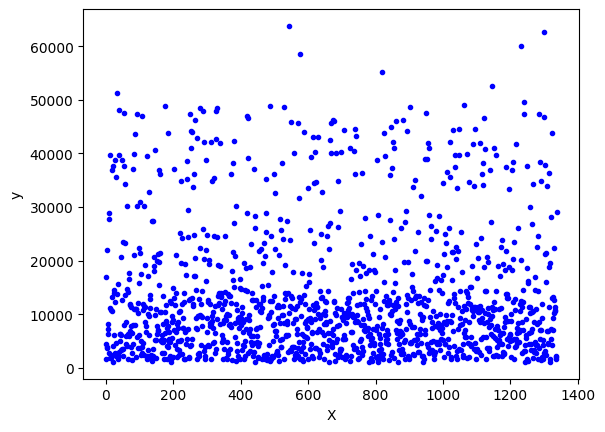

In [17]:
plt.plot(df['charges'],'b.')
plt.xlabel('X')
plt.ylabel('y')

<Axes: >

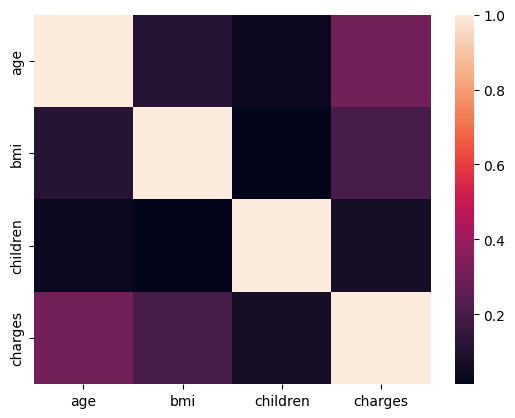

In [18]:
sns.heatmap(df.corr(numeric_only=True))

<Axes: xlabel='charges', ylabel='Count'>

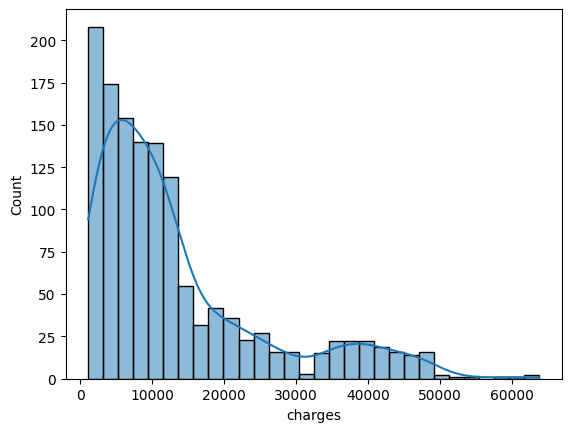

In [19]:
sns.histplot(df['charges'],kde=True)

<Axes: xlabel='age', ylabel='Count'>

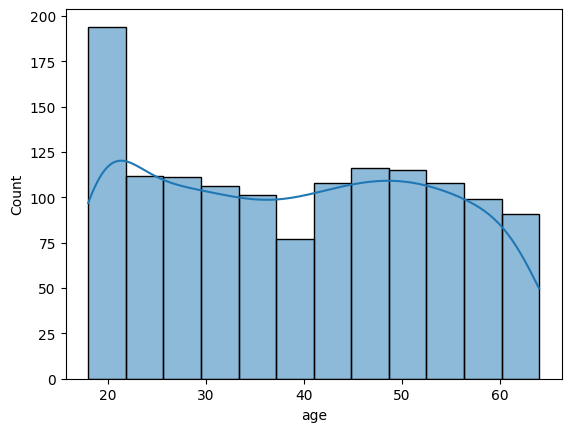

In [20]:
sns.histplot(df['age'], kde=True)


<Axes: xlabel='bmi', ylabel='charges'>

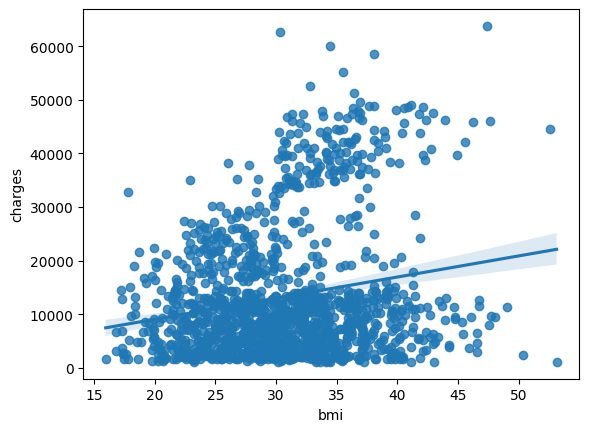

In [21]:
sns.regplot(
    x='bmi',
    y='charges',
    data=df
    
)

<Axes: xlabel='smoker', ylabel='charges'>

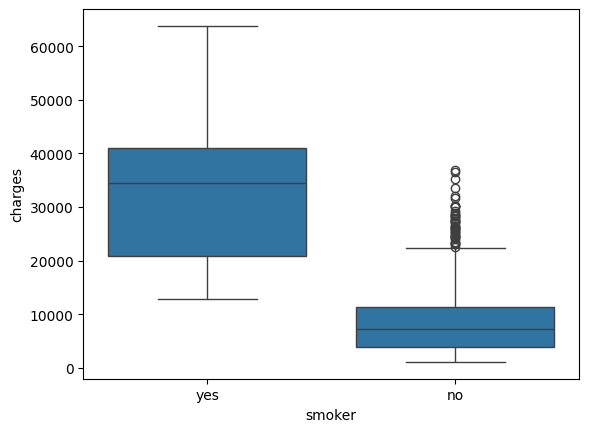

In [22]:
sns.boxplot(x='smoker',y='charges',data=df)

<Axes: xlabel='sex', ylabel='charges'>

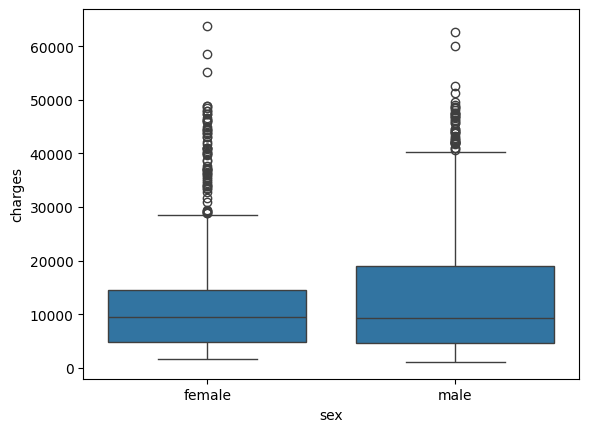

In [23]:
sns.boxplot(x='sex',y='charges',data=df)

In [24]:
df.skew(numeric_only=True)

age        0.06
bmi        0.28
children   0.94
charges    1.52
dtype: float64

## feature Engineering:

Two new features are created:

- bmi_age = BMI × Age
- age_squared = Age²

These features help capture non-linear relationships.

In [25]:
df = df.copy()

In [26]:
df['bmi_age'] = df['bmi'] * df['age']
df['age_squared'] = df['age'] ** 2

In [27]:
df.head()

,age,sex,bmi,children,smoker,region,charges,bmi_age,age_squared
0,19,female,27.90,0,yes,southwest,16884.92,530.10,361
1,18,male,33.77,1,no,southeast,1725.55,607.86,324
2,28,male,33.00,3,no,southeast,4449.46,924.00,784
3,33,male,22.70,0,no,northwest,21984.47,749.26,1089
4,32,male,28.88,0,no,northwest,3866.86,924.16,1024


## Check Correlation:

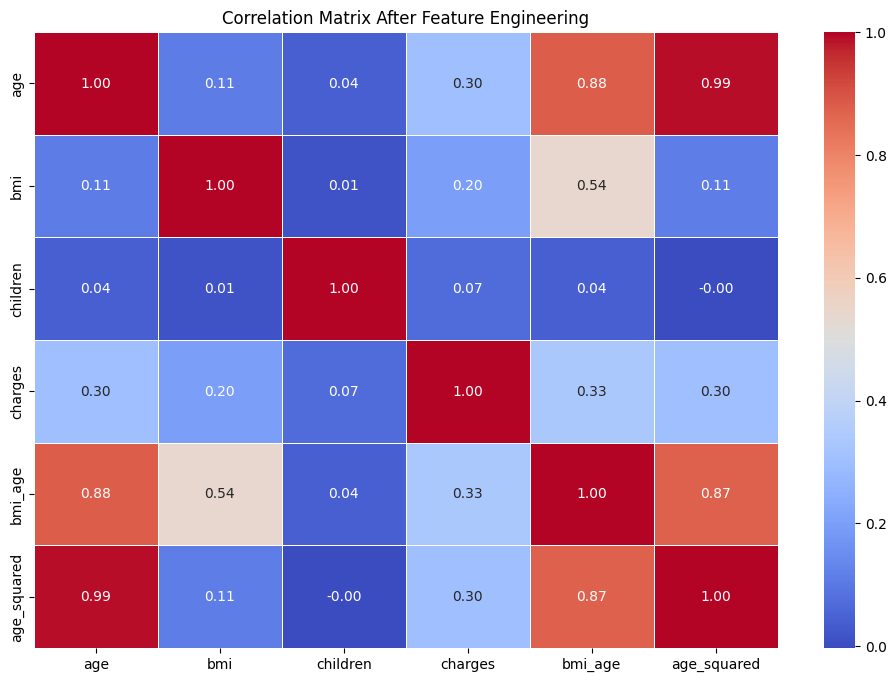

In [28]:
plt.figure(figsize=(12,8))

corr = df.corr(numeric_only=True)

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix After Feature Engineering")

plt.show()

## Define Features and Target:

In [29]:
X = df.drop('charges',axis=1)
y = df['charges']

## Train-Test Split:

In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print(f"Training Samples : {X_train.shape[0]}")
print(f"Testing Samples  : {X_test.shape[0]}")

Training Samples : 1070
Testing Samples  : 268


## Numerical and Categorical Features:

In [31]:
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Features")
print(numeric_features)

print("\nCategorical Features")
print(categorical_features)

Numerical Features
['age', 'bmi', 'children', 'bmi_age', 'age_squared']

Categorical Features
['sex', 'smoker', 'region']


## Numerical Pipeline:

In [32]:
numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),

        (
            "scaler",
            StandardScaler()
        )
    ]
)

## Categorical Pipeline:

In [33]:
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),

        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

## Column Transformer:

In [34]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),

        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

## Create Evaluation Function:

In [35]:
def evaluate_model(model, X_train, X_test, y_train, y_test):

    start = time.time()

    model.fit(X_train, y_train)

    training_time = time.time() - start

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    cv_score = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="r2"
    ).mean()

    return {

        "Train R2":
        r2_score(y_train, train_pred),

        "Test R2":
        r2_score(y_test, test_pred),

        "MAE":
        mean_absolute_error(y_test, test_pred),

        "MSE":
        mean_squared_error(y_test, test_pred),

        "RMSE":
        np.sqrt(
            mean_squared_error(y_test, test_pred)
        ),

        "MAPE":
        mean_absolute_percentage_error(
            y_test,
            test_pred
        ),

        "Explained Variance":
        explained_variance_score(
            y_test,
            test_pred
        ),

        "CV Score":
        cv_score,

        "Training Time":
        training_time
    }

## Model Pipeline Function:

In [37]:
def build_pipeline(model):

    pipeline = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),

            (
                "model",
                model
            )
        ]
    )

    return pipeline


## Result Directory
results = {}

## Visualization Function:

In [38]:
def plot_predictions(
    y_true,
    y_pred,
    model_name
):

    plt.figure(figsize=(7,7))

    plt.scatter(
        y_true,
        y_pred,
        alpha=0.6
    )

    plt.plot(
        [
            y_true.min(),
            y_true.max()
        ],
        [
            y_true.min(),
            y_true.max()
        ],
        color="red",
        linestyle="--"
    )

    plt.xlabel("Actual")

    plt.ylabel("Predicted")

    plt.title(f"{model_name}")

    plt.show()

## Residual Plot Function:

In [39]:
def residual_plot(
    y_true,
    y_pred,
    model_name
):

    residuals = y_true - y_pred

    plt.figure(figsize=(8,5))

    sns.scatterplot(
        x=y_pred,
        y=residuals
    )

    plt.axhline(
        y=0,
        color="red",
        linestyle="--"
    )

    plt.xlabel("Predicted")

    plt.ylabel("Residuals")

    plt.title(
        f"Residual Plot - {model_name}"
    )

    plt.show()

## Model Directory:

In [42]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(random_state=RANDOM_STATE),
    "Lasso Regression": Lasso(),
    "ElasticNet": ElasticNet(),
    "SGD Regressor": SGDRegressor(random_state=RANDOM_STATE)
}

In [43]:
# Train and Evaluate
results = {}

for name, model in models.items():

    pipeline = build_pipeline(model)

    metrics = evaluate_model(
        pipeline,
        X_train,
        X_test,
        y_train,
        y_test
    )

    results[name] = metrics

In [44]:
##result Table:
results_df = (
    pd.DataFrame(results)
    .T
    .sort_values("Test R2", ascending=False)
)

results_df

,Train R2,Test R2,MAE,MSE,RMSE,MAPE,Explained Variance,CV Score,Training Time
SGD Regressor,0.74,0.79,4066.92,33195521.16,5761.56,0.45,0.79,0.73,0.00
Lasso Regression,0.74,0.78,4101.32,33389904.57,5778.40,0.47,0.79,0.73,0.00
Linear Regression,0.74,0.78,4101.31,33401228.36,5779.38,0.47,0.79,0.73,0.01
Ridge Regression,0.74,0.78,4107.76,33405382.46,5779.74,0.47,0.79,0.73,0.00
ElasticNet,0.51,0.54,6424.96,72107920.91,8491.64,0.95,0.54,0.50,0.00


## Comparison Plot:

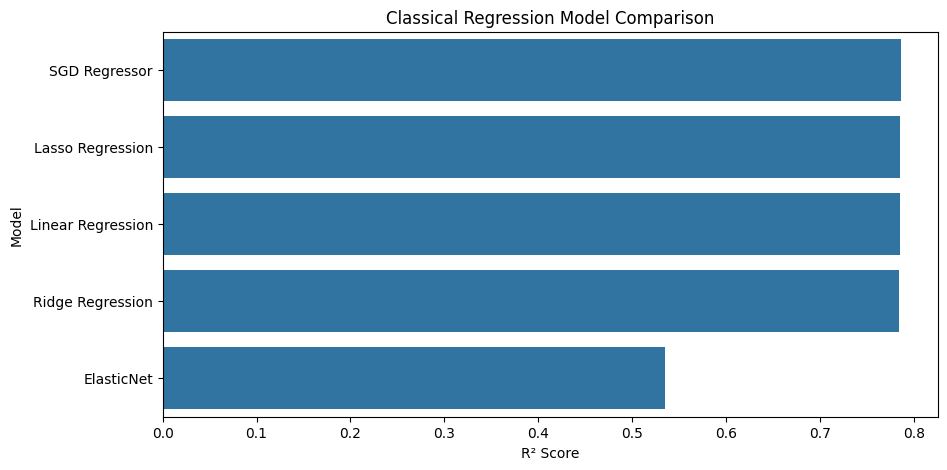

In [45]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=results_df.reset_index(),
    x="Test R2",
    y="index"
)

plt.title("Classical Regression Model Comparison")
plt.xlabel("R² Score")
plt.ylabel("Model")

plt.show()

## Best Model:

In [46]:
best_classical = results_df.index[0]

print(f"Best Classical Model : {best_classical}")

Best Classical Model : SGD Regressor


# Tree Based Regression Model:

In [48]:
tree_models = {

    "Decision Tree": DecisionTreeRegressor(
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

}

In [49]:
tree_results = {}

for name, model in tree_models.items():

    pipeline = build_pipeline(model)

    metrics = evaluate_model(
        pipeline,
        X_train,
        X_test,
        y_train,
        y_test
    )

    tree_results[name] = metrics

In [50]:
tree_results_df = (
    pd.DataFrame(tree_results)
      .T
      .sort_values(
          by="Test R2",
          ascending=False
      )
)

tree_results_df

,Train R2,Test R2,MAE,MSE,RMSE,MAPE,Explained Variance,CV Score,Training Time
Random Forest,0.98,0.87,2419.61,20558303.30,4534.13,0.30,0.87,0.83,0.11
Extra Trees,1.00,0.86,2390.41,22438533.91,4736.93,0.27,0.86,0.81,0.06
Decision Tree,1.00,0.79,2554.57,32214086.17,5675.75,0.28,0.79,0.70,0.02


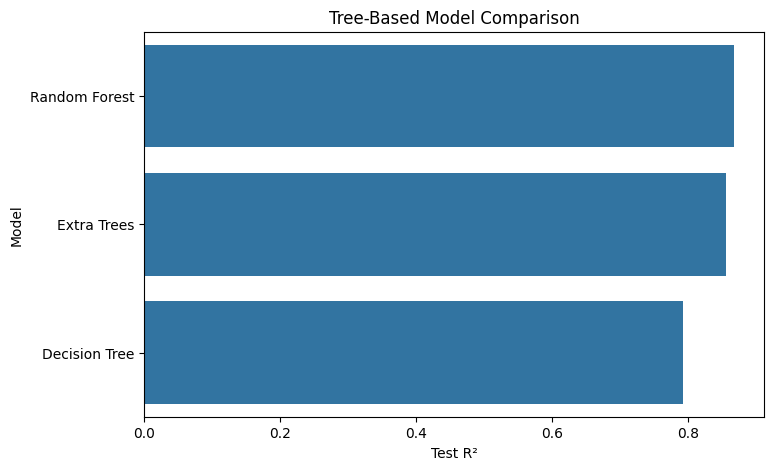

In [51]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=tree_results_df.reset_index(),
    x="Test R2",
    y="index"
)

plt.title("Tree-Based Model Comparison")
plt.xlabel("Test R²")
plt.ylabel("Model")

plt.show()

In [52]:
best_tree = tree_results_df.index[0]

print(f"Best Tree Model : {best_tree}")

Best Tree Model : Random Forest


In [53]:
rf_pipeline = build_pipeline(
    RandomForestRegressor(
        n_estimators=200,
        random_state=RANDOM_STATE
    )
)

rf_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers co

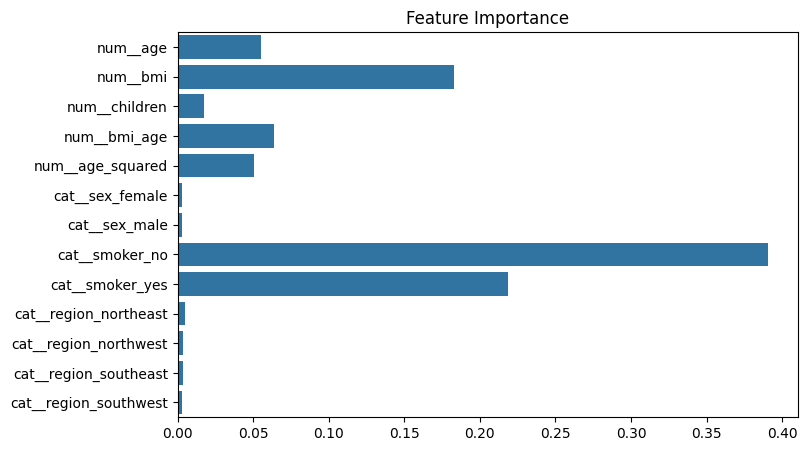

In [55]:
# Train model
rf_pipeline.fit(X_train, y_train)

# Feature importance
importance = rf_pipeline.named_steps["model"].feature_importances_

# Feature names
feature_names = rf_pipeline.named_steps["preprocessor"].get_feature_names_out()

# Plot
plt.figure(figsize=(8,5))
sns.barplot(x=importance, y=feature_names)
plt.title("Feature Importance")
plt.show()

# Boosting Regression Model:

In [56]:

# Boosting Regression Models

boosting_models = {

    "Gradient Boosting":
        GradientBoostingRegressor(
            random_state=RANDOM_STATE
        ),

    "AdaBoost":
        AdaBoostRegressor(
            random_state=RANDOM_STATE
        ),

    "XGBoost":
        XGBRegressor(
            objective="reg:squarederror",
            random_state=RANDOM_STATE,
            verbosity=0
        ),

    "LightGBM":
        LGBMRegressor(
            random_state=RANDOM_STATE,
            verbose=-1
        ),

    "CatBoost":
        CatBoostRegressor(
            random_state=RANDOM_STATE,
            verbose=0
        )
}

## Train and evaluate model:

In [57]:
for name, model in boosting_models.items():

    pipeline = build_pipeline(model)

    metrics = evaluate_model(
        pipeline,
        X_train,
        X_test,
        y_train,
        y_test
    )

    results[name] = metrics

## Result Table

In [58]:

results_df = (
    pd.DataFrame(results)
      .T
      .sort_values(
          by="Test R2",
          ascending=False
      )
)

results_df

,Train R2,Test R2,MAE,MSE,RMSE,MAPE,Explained Variance,CV Score,Training Time
Gradient Boosting,0.91,0.88,2463.64,19212789.10,4383.24,0.30,0.88,0.84,0.11
CatBoost,0.96,0.87,2540.18,20940646.83,4576.10,0.31,0.87,0.83,0.37
LightGBM,0.95,0.86,2609.60,21175447.34,4601.68,0.35,0.86,0.82,0.39
XGBoost,1.00,0.86,2555.13,21888511.79,4678.52,0.34,0.86,0.79,0.13
AdaBoost,0.79,0.80,4837.76,31118665.04,5578.41,0.98,0.86,0.79,0.01
SGD Regressor,0.74,0.79,4066.92,33195521.16,5761.56,0.45,0.79,0.73,0.00
Lasso Regression,0.74,0.78,4101.32,33389904.57,5778.40,0.47,0.79,0.73,0.00
Linear Regression,0.74,0.78,4101.31,33401228.36,5779.38,0.47,0.79,0.73,0.01
Ridge Regression,0.74,0.78,4107.76,33405382.46,5779.74,0.47,0.79,0.73,0.00
ElasticNet,0.51,0.54,6424.96,72107920.91,8491.64,0.95,0.54,0.50,0.00


## Comparison plot:

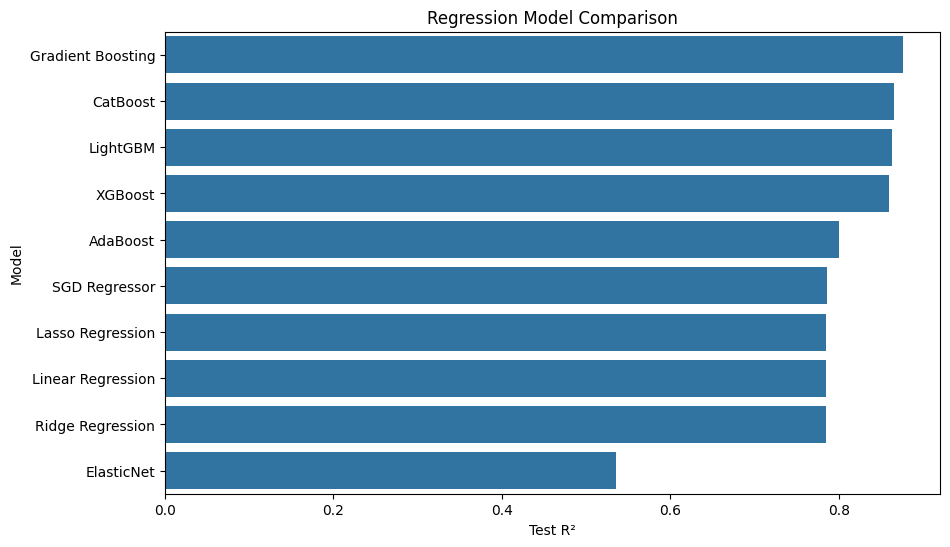

In [62]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=results_df.reset_index(),
    x="Test R2",
    y="index"
)

plt.title("Regression Model Comparison")
plt.xlabel("Test R²")
plt.ylabel("Model")

plt.show()

In [63]:
best_model = results_df.index[0]

print(f"🏆 Best Model : {best_model}")

🏆 Best Model : Gradient Boosting


# HyperParameter Tuning:

In [71]:
from scipy.stats import randint

gb_pipeline = build_pipeline(
    GradientBoostingRegressor(random_state=RANDOM_STATE)
)

gb_params = {
    "model__n_estimators": randint(100, 500),
    "model__learning_rate": uniform(0.01, 0.2),
    "model__max_depth": randint(2, 8),
    "model__min_samples_split": randint(2, 10),
    "model__min_samples_leaf": randint(1, 5),
    "model__subsample": uniform(0.7, 0.3)
}


gb_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=gb_params,
    n_iter=20,
    cv=5,
    scoring="r2",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

gb_search.fit(X_train, y_train)

print("Best GB Parameters:")
print(gb_search.best_params_)
print(f"Best CV Score: {gb_search.best_score_:.4f}")

Best GB Parameters:
{'model__learning_rate': np.float64(0.024910128735954166), 'model__max_depth': 2, 'model__min_samples_leaf': 4, 'model__min_samples_split': 2, 'model__n_estimators': 235, 'model__subsample': np.float64(0.7016566351370807)}
Best CV Score: 0.8515


# Optuna:

In [73]:
def objective(trial):

    model = build_pipeline(
        GradientBoostingRegressor(
            n_estimators=trial.suggest_int("n_estimators", 100, 500),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3),
            max_depth=trial.suggest_int("max_depth", 2, 8),
            min_samples_split=trial.suggest_int("min_samples_split", 2, 10),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 5),
            subsample=trial.suggest_float("subsample", 0.7, 1.0),
            random_state=RANDOM_STATE
        )
    )

    score = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="r2",
        n_jobs=-1
    ).mean()

    return score

In [74]:
study = optuna.create_study(direction="maximize")

study.optimize(
    objective,
    n_trials=30,
    show_progress_bar=True
)

[I 2026-08-07 01:47:37,550] A new study created in memory with name: no-name-bed1f695-ce31-4aae-8d8a-3c67b781940a


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-08-07 01:47:37,704] Trial 0 finished with value: 0.8358564934258972 and parameters: {'n_estimators': 224, 'learning_rate': 0.14733151646499507, 'max_depth': 2, 'min_samples_split': 9, 'min_samples_leaf': 5, 'subsample': 0.7670482030965949}. Best is trial 0 with value: 0.8358564934258972.
[I 2026-08-07 01:47:37,887] Trial 1 finished with value: 0.7934731436899958 and parameters: {'n_estimators': 163, 'learning_rate': 0.1915473414347986, 'max_depth': 5, 'min_samples_split': 7, 'min_samples_leaf': 2, 'subsample': 0.9448954677856531}. Best is trial 0 with value: 0.8358564934258972.
[I 2026-08-07 01:47:38,052] Trial 2 finished with value: 0.8218688959086817 and parameters: {'n_estimators': 319, 'learning_rate': 0.19508561147259654, 'max_depth': 2, 'min_samples_split': 10, 'min_samples_leaf': 2, 'subsample': 0.8396812931227173}. Best is trial 0 with value: 0.8358564934258972.
[I 2026-08-07 01:47:38,244] Trial 3 finished with value: 0.8166083337634644 and parameters: {'n_estimators': 

In [ ]:
print("Best Parameters:")
print(study.best_params)

print("\nBest CV Score:")
print(f"{study.best_value:.4f}")

Best Parameters:
{'n_estimators': 237, 'learning_rate': 0.06880071753930012, 'max_depth': 2, 'min_samples_split': 10, 'min_samples_leaf': 1, 'subsample': 0.9072206175996562}

Best CV Score:
0.8480


In [76]:
#Train Final Tuned Model
best_gb = build_pipeline(
    GradientBoostingRegressor(
        **study.best_params,
        random_state=RANDOM_STATE
    )
)

best_gb.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers co

In [77]:
gb_metrics = evaluate_model(
    best_gb,
    X_train,
    X_test,
    y_train,
    y_test
)

results["Gradient Boosting (Optuna)"] = gb_metrics

In [78]:
final_results = (
    pd.DataFrame(results)
      .T
      .sort_values("Test R2", ascending=False)
)

final_results

,Train R2,Test R2,MAE,MSE,RMSE,MAPE,Explained Variance,CV Score,Training Time
Gradient Boosting (Optuna),0.90,0.88,2385.59,18175219.15,4263.24,0.30,0.88,0.85,0.15
Gradient Boosting,0.91,0.88,2463.64,19212789.10,4383.24,0.30,0.88,0.84,0.11
CatBoost,0.96,0.87,2540.18,20940646.83,4576.10,0.31,0.87,0.83,0.37
LightGBM,0.95,0.86,2609.60,21175447.34,4601.68,0.35,0.86,0.82,0.39
XGBoost,1.00,0.86,2555.13,21888511.79,4678.52,0.34,0.86,0.79,0.13
AdaBoost,0.79,0.80,4837.76,31118665.04,5578.41,0.98,0.86,0.79,0.01
SGD Regressor,0.74,0.79,4066.92,33195521.16,5761.56,0.45,0.79,0.73,0.00
Lasso Regression,0.74,0.78,4101.32,33389904.57,5778.40,0.47,0.79,0.73,0.00
Linear Regression,0.74,0.78,4101.31,33401228.36,5779.38,0.47,0.79,0.73,0.01
Ridge Regression,0.74,0.78,4107.76,33405382.46,5779.74,0.47,0.79,0.73,0.00


In [79]:
import joblib

joblib.dump(best_model, "best_model.pkl")

print("Model saved successfully!")

Model saved successfully!


# Conclusion:

In this project, multiple machine learning regression models were developed and evaluated to predict medical insurance charges.
The workflow included data preprocessing, exploratory data analysis, feature engineering, model training, and hyperparameter tuning.

A total of 14 regression models were compared, including linear, tree-based, and boosting algorithms. Hyperparameter optimization using RandomizedSearchCV and Optuna improved the performance of the top-performing models. Among all the models, the optimized Gradient Boosting Regressor achieved the best predictive performance on the test dataset.

The final model was saved using Joblib and is ready for deployment in applications such as Streamlit or FastAPI. This project demonstrates a complete end-to-end machine learning workflow, from data preparation to model optimization and deployment.